In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import torch
import matplotlib.pyplot as plt

# Load MEaSUREs Phase-Based Antarctica Ice Velocity Map

We use [MEaSUREs Phase-Based Antarctica Ice Velocity Map, Version 1](https://nsidc.org/data/nsidc-0754/versions/1)

Reference:
- *Mouginot, J., Rignot, E. & Scheuchl, B. (2019). MEaSUREs Phase-Based Antarctica Ice Velocity Map. (NSIDC-0754, Version 1). [Data Set]. Boulder, Colorado USA. NASA National Snow and Ice Data Center Distributed Active Archive Center. https://doi.org/10.5067/PZ3NJ5RXRH10. Date Accessed 10-02-2025.*

In [2]:
# TODO define local path or full path to ice velocity data
ice_vel = xr.load_dataset("/home/kim/data/nsidc/antarctic_ice_vel_phase_map_v01.nc")

# Define new variable: speed V: sqrt(VX**2 + VY**2)
# hypot is numerically more stable than sqrt(VX**2 + VY**2)
ice_vel["V"] = np.hypot(ice_vel["VX"], ice_vel["VY"])

## Subset Ross Island region

In [6]:
# import region bounds
from regions import ROSS_ISLAND_BOUNDS

# assign region bounds
x_min = ROSS_ISLAND_BOUNDS["x_min"]
x_max = ROSS_ISLAND_BOUNDS["x_max"]
y_min = ROSS_ISLAND_BOUNDS["y_min"]
y_max = ROSS_ISLAND_BOUNDS["y_max"]

# NOTE: x, y ordering!
ice_vel_ross_island = ice_vel.sel(
    x = slice(x_min, x_max), 
    y = slice(y_max, y_min))

ice_vel_ross_island

<xarray.Dataset> Size: 9MB
Dimensions:       (x: 445, y: 400)
Coordinates:
  * x             (x) float64 4kB 1.601e+05 1.606e+05 ... 3.594e+05 3.599e+05
  * y             (y) float64 3kB -1.22e+06 -1.221e+06 ... -1.399e+06 -1.4e+06
    lat           (y, x) float64 1MB -78.71 -78.71 -78.71 ... -76.76 -76.75
    lon           (y, x) float64 1MB 172.5 172.5 172.5 ... 165.6 165.6 165.6
Data variables:
    coord_system  |S1 1B b''
    VX            (y, x) float32 712kB -70.48 -69.45 -69.45 ... nan nan nan
    VY            (y, x) float32 712kB -776.0 -774.6 -773.0 ... nan nan nan
    STDX          (y, x) float32 712kB 6.843 9.158 9.38 8.58 ... nan nan nan nan
    STDY          (y, x) float32 712kB 15.99 16.51 17.3 16.77 ... nan nan nan
    ERRX          (y, x) float32 712kB 0.6025 0.8395 0.8598 ... nan nan nan
    ERRY          (y, x) float32 712kB 1.408 1.514 1.586 1.538 ... nan nan nan
    CNT           (y, x) int32 712kB 129 119 119 119 122 123 121 ... 0 0 0 0 0 0
    SOURCE        (y, x) int8 178kB 1 1 1 1 1 1 1 1 1 1 ... 0 0 0 0 0 0 0 0 0 0
    V             (y, x) float32 712kB 779.2 777.7 776.1 775.3 ... nan nan nan
Attributes: (12/27)
    Conventions:               CF-1.6
    Metadata_Conventions:      CF-1.6, Unidata Dataset Discovery v1.0, GDS v2.0
    standard_name_vocabulary:  CF Standard Name Table (v22, 12 February 2013)
    id:                        v_mix.v8Jul2019.nc
    title:                     MEaSURES Antarctica Ice Velocity Map 450m spacing
    product_version:            
    ...                        ...
    time_coverage_start:       1995-01-01
    time_coverage_end:         2016-12-31
    project:                   NASA/MEaSUREs
    creator_name:              J. Mouginot
    comment:                    
    license:                   No restrictions on access or use.

# Interpolate the mask to subset region

data stays at og 450m grid. 

In [36]:
tighter_ice_shelf_mask = xr.load_dataarray("data/tighter_ice_shelf_mask.nc")

mask_for_ice_vel = tighter_ice_shelf_mask.interp(
    x = ice_vel_ross.x, 
    y = ice_vel_ross.y, 
    method = "nearest"
)

ice_vel_ross_on_target = ice_vel_ross.V.where(mask_for_ice_vel == 3)
ice_vel_ross_ds_on_target = ice_vel_ross.where(mask_for_ice_vel == 3)

# Load MODIS background

In [3]:
modis_ross = torch.load("data/modis/moa125_2014_hp1_v01_ross_with_grid_no_ocean.pt", weights_only = False)

# Visualise

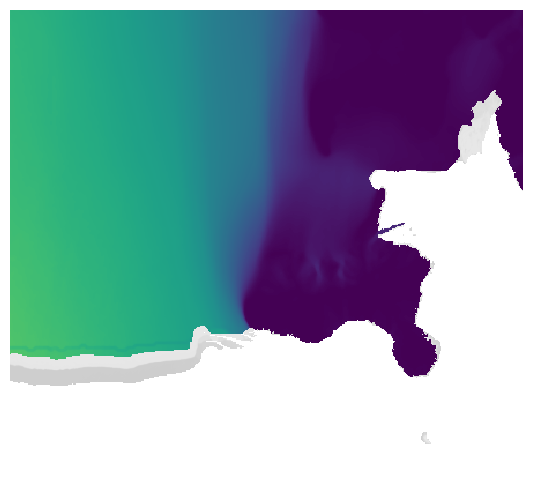

: 

In [ ]:
fig, ax = plt.subplots(figsize = (8, 6))

# 1) MODIS as background (draw first)
ax.pcolormesh(
    modis_ross[0],
    modis_ross[1], 
    modis_ross[2],
    cmap = "gray",
    # softer greys
    vmin = -30_000, 
    vmax = 30_000,
    # as less saturated background
    alpha = 0.4,
    zorder = 0,
)

# 2) ice vel on top (draw second)
pcm = ax.pcolormesh(
    ice_vel_ross_island.x,
    ice_vel_ross_island.y,
    ice_vel_ross_island.V,
    cmap = "viridis",
    # Fix these limits for consistency
    vmin = 0,
    vmax = 1200,
    shading = "auto",
    # 1.0 for full opacity & consistency
    alpha = 1.0,
    zorder = 1,
)

ax.set_aspect("equal")
ax.set_axis_off()

# crop
ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

fig.savefig("figures/ice_vel_ross_island.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)
plt.show()

# cmap

In [8]:
cmap = "viridis"
dpi = 300

# 1 x N gradient
grad = np.linspace(0, 1, 2048)[None, :]

fig = plt.figure(figsize = (6, 0.6), dpi = dpi)
ax = fig.add_axes([0, 0, 1, 1]) 
ax.imshow(grad, aspect = "auto", cmap = cmap)
ax.set_axis_off()

fig.savefig("figures/cmap/viridis_bar.png", dpi = dpi, transparent = True, bbox_inches = "tight", pad_inches = 0)
plt.close(fig)